In [3]:
# Cell 1: Cài thư viện mat73 để đọc file MATLAB .mat
!pip install -q mat73

In [8]:
# Cell 2: Import các thư viện cần dùng
# - os: tìm file dữ liệu
# - hashlib: tính checksum
# - numpy: xử lý mảng tín hiệu
# - pandas: xử lý metadata
# - matplotlib: vẽ tín hiệu
# - mat73: đọc file .mat phiên bản MATLAB 7.3
import os
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mat73

In [9]:
# Cell 3: Tìm tất cả file .mat trong thư mục dữ liệu của Kaggle
# Mục đích: xác định chính xác đường dẫn file PulseDB đang sử dụng
mat_files = []

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f.endswith(".mat"):
            mat_files.append(os.path.join(root, f))

print("Số file .mat:", len(mat_files))
print(*mat_files[:10], sep="\n")

Số file .mat: 5
/kaggle/input/datasets/weinanwangrutgers/pulsedb-balanced-training-and-testing/VitalDB_AAMI_Cal_Subset.mat
/kaggle/input/datasets/weinanwangrutgers/pulsedb-balanced-training-and-testing/VitalDB_Train_Subset.mat
/kaggle/input/datasets/weinanwangrutgers/pulsedb-balanced-training-and-testing/VitalDB_AAMI_Test_Subset.mat
/kaggle/input/datasets/weinanwangrutgers/pulsedb-balanced-training-and-testing/VitalDB_CalFree_Test_Subset.mat
/kaggle/input/datasets/weinanwangrutgers/pulsedb-balanced-training-and-testing/VitalDB_CalBased_Test_Subset.mat


In [10]:
# Cell 4: Đọc file .mat
# Mục đích: kiểm tra file có đọc được và xem cấu trúc cấp cao nhất
file_path = mat_files[0]

data = mat73.loadmat(file_path)

print("File:", file_path)
print("Keys:", data.keys())

File: /kaggle/input/datasets/weinanwangrutgers/pulsedb-balanced-training-and-testing/VitalDB_AAMI_Cal_Subset.mat
Keys: dict_keys(['Subset'])


In [12]:
# Cell 5: Truy cập phần dữ liệu "Subset"
# Mục đích: kiểm tra các trường metadata và tín hiệu có đúng schema không
subset = data["Subset"]

print("Subset keys:")
print(subset.keys())

Subset keys:
dict_keys(['Age', 'BMI', 'DBP', 'Gender', 'Height', 'SBP', 'Signals', 'Subject', 'Weight'])


In [13]:
# Cell 6: Kiểm tra cấu trúc Signals
# Shape dự kiến: (số_segment, 3, 1250)
# 3 kênh tương ứng ECG, PPG, ABP
signals = subset["Signals"]

print("Signals shape:", np.shape(signals))
print("Signals dtype:", np.array(signals).dtype)

Signals shape: (70212, 3, 1250)
Signals dtype: float64


In [14]:
# Cell 7: Lấy 1.000 segment đầu tiên để kiểm tra
# Không cần phân tích toàn bộ 70.212 segment vì task yêu cầu tối thiểu 1.000 segment
signals_1000 = subset["Signals"][:1000]

print("Shape:", signals_1000.shape)

Shape: (1000, 3, 1250)


In [15]:
# Cell 8: Kiểm tra missing value (NaN) trong 3 loại tín hiệu
# Channel 0: ECG
# Channel 1: PPG
# Channel 2: ABP
print("ECG NaN:", np.isnan(signals_1000[:, 0, :]).sum())
print("PPG NaN:", np.isnan(signals_1000[:, 1, :]).sum())
print("ABP NaN:", np.isnan(signals_1000[:, 2, :]).sum())

ECG NaN: 0
PPG NaN: 0
ABP NaN: 0


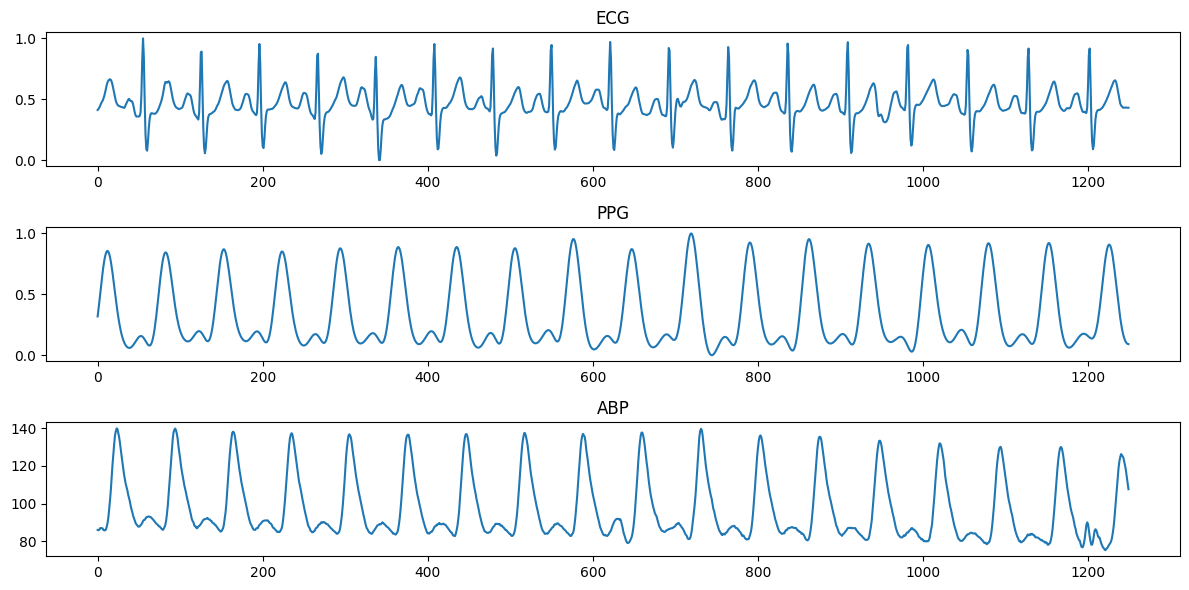

In [16]:
# Cell 9: Vẽ ECG, PPG và ABP của segment đầu tiên
# Mục đích: kiểm tra trực quan xem dữ liệu tín hiệu có đọc đúng hay không
plt.figure(figsize=(12, 6))

plt.subplot(3, 1, 1)
plt.plot(signals_1000[0, 0, :])
plt.title("ECG")

plt.subplot(3, 1, 2)
plt.plot(signals_1000[0, 1, :])
plt.title("PPG")

plt.subplot(3, 1, 3)
plt.plot(signals_1000[0, 2, :])
plt.title("ABP")

plt.tight_layout()
plt.show()

In [17]:
# Cell 10: Kiểm tra schema của metadata
# Mục đích: xác nhận các trường cần thiết đều tồn tại
# và kiểm tra kích thước + một vài giá trị mẫu
metadata_keys = ["Subject", "Age", "Gender", "Height", "Weight", "BMI", "SBP", "DBP"]

for key in metadata_keys:
    arr = np.asarray(subset[key]).squeeze()
    print(f"{key}: shape={arr.shape}, first 5={arr[:5]}")

Subject: shape=(70212,), first 5=['p000238_1' 'p000238_1' 'p000238_1' 'p000238_1' 'p000238_1']
Age: shape=(70212,), first 5=[26. 26. 26. 26. 26.]
Gender: shape=(70212,), first 5=['M' 'M' 'M' 'M' 'M']
Height: shape=(70212,), first 5=[183.9 183.9 183.9 183.9 183.9]
Weight: shape=(70212,), first 5=[89.05 89.05 89.05 89.05 89.05]
BMI: shape=(70212,), first 5=[26.3 26.3 26.3 26.3 26.3]
SBP: shape=(70212,), first 5=[134.86043824 129.28857166 122.43691326 116.37387465 116.58896216]
DBP: shape=(70212,), first 5=[82.16827899 74.95978767 77.81818022 75.14700393 73.8741986 ]


In [18]:
# Cell 11: Tạo bảng metadata cho 1.000 segment
# Mục đích:
# - ánh xạ metadata về dạng dễ kiểm tra
# - kiểm tra missing value
# - kiểm tra subject_id
n = 1000

metadata = {}

for key in ["Subject", "Age", "Gender", "Height", "Weight", "BMI", "SBP", "DBP"]:
    metadata[key] = np.asarray(subset[key]).squeeze()[:n]

df_meta = pd.DataFrame({
    "segment_idx": np.arange(n),
    "subject_id": metadata["Subject"],
    "age": metadata["Age"],
    "gender": metadata["Gender"],
    "height_cm": metadata["Height"],
    "weight_kg": metadata["Weight"],
    "bmi": metadata["BMI"],
    "sbp": metadata["SBP"],
    "dbp": metadata["DBP"],
})

print("Số đoạn:", len(df_meta))
print("Số subject khác nhau:", df_meta["subject_id"].nunique())
print("\nMissing:")
print(df_meta.isna().sum())

print("\n5 dòng đầu:")
display(df_meta.head())

Số đoạn: 1000
Số subject khác nhau: 2

Missing:
segment_idx    0
subject_id     0
age            0
gender         0
height_cm      0
weight_kg      0
bmi            0
sbp            0
dbp            0
dtype: int64

5 dòng đầu:


,segment_idx,subject_id,age,gender,height_cm,weight_kg,bmi,sbp,dbp
0,0,p000238_1,26.0,M,183.9,89.05,26.3,134.860438,82.168279
1,1,p000238_1,26.0,M,183.9,89.05,26.3,129.288572,74.959788
2,2,p000238_1,26.0,M,183.9,89.05,26.3,122.436913,77.818180
3,3,p000238_1,26.0,M,183.9,89.05,26.3,116.373875,75.147004
4,4,p000238_1,26.0,M,183.9,89.05,26.3,116.588962,73.874199


In [19]:
# Cell 12: Kiểm tra độ dài của từng kênh
# Mục đích: xác nhận mỗi segment có 1.250 samples
print("ECG length:", signals_1000[:, 0, :].shape[1])
print("PPG length:", signals_1000[:, 1, :].shape[1])
print("ABP length:", signals_1000[:, 2, :].shape[1])

print("\nExpected:")
print("3 channels: ECG, PPG, ABP")
print("1250 samples/segment")

ECG length: 1250
PPG length: 1250
ABP length: 1250

Expected:
3 channels: ECG, PPG, ABP
1250 samples/segment


In [20]:
# Cell 13: Kiểm tra metadata bị trùng
# Kiểm tra 1: toàn bộ dòng metadata có trùng hoàn toàn không
# Test metadata trùng
duplicate_count = df_meta.duplicated().sum()

print("Số dòng metadata trùng hoàn toàn:", duplicate_count)

# Kiểm tra subject_id + segment_idx có bị trùng không
key_duplicate_count = df_meta.duplicated(
    subset=["subject_id", "segment_idx"]
).sum()

print("Số khóa subject_id + segment_idx bị trùng:", key_duplicate_count)

Số dòng metadata trùng hoàn toàn: 0
Số khóa subject_id + segment_idx bị trùng: 0


In [21]:
# Cell 14: Kiểm tra số lượng và thứ tự kênh
# Reader của project đang quy ước:
# Channel 0 -> ECG
# Channel 1 -> PPG
# Channel 2 -> ABP
n_channels = signals_1000.shape[1]

print("Số kênh:", n_channels)

assert n_channels == 3, f"Expected 3 channels, got {n_channels}"

print("Channel mapping:")
print("Channel 0 -> ECG")
print("Channel 1 -> PPG")
print("Channel 2 -> ABP")
print("PASS: số kênh đúng")

Số kênh: 3
Channel mapping:
Channel 0 -> ECG
Channel 1 -> PPG
Channel 2 -> ABP
PASS: số kênh đúng


In [22]:
import hashlib

file_path = "/kaggle/input/datasets/weinanwangrutgers/pulsedb-balanced-training-and-testing/VitalDB_AAMI_Cal_Subset.mat"

sha256 = hashlib.sha256()

with open(file_path, "rb") as f:
    for chunk in iter(lambda: f.read(64 * 1024 * 1024), b""):
        sha256.update(chunk)

print("SHA256:", sha256.hexdigest())

SHA256: bc68fc239d3809f20cda01bb55eeae7aee88912f8143e0c4cde18d9c4384dcde


In [24]:
# ============================================================
# SUMMARY / EVIDENCE
# ============================================================

print("=" * 60)
print("PulseDB - VitalDB_AAMI_Cal_Subset validation summary")
print("=" * 60)

print("\n[Dataset]")
print("File: VitalDB_AAMI_Cal_Subset.mat")
print("Signals shape:", signals.shape)
print("Number of segments:", signals.shape[0])
print("Number of channels:", signals.shape[1])
print("Samples per segment:", signals.shape[2])

print("\n[Channel mapping]")
print("Channel 0 -> ECG")
print("Channel 1 -> PPG")
print("Channel 2 -> ABP")

print("\n[Validation - first 1000 segments]")
print("Segments checked:", 1000)
print("ECG NaN:", np.isnan(signals_1000[:, 0, :]).sum())
print("PPG NaN:", np.isnan(signals_1000[:, 1, :]).sum())
print("ABP NaN:", np.isnan(signals_1000[:, 2, :]).sum())

print("\n[Metadata]")
print("Unique subjects:", df_meta["subject_id"].nunique())
print("Missing metadata:")
print(df_meta.isna().sum())

print("\n[Duplicate check]")
print("Duplicate metadata rows:", duplicate_count)
print("Duplicate subject_id + segment_idx:", key_duplicate_count)

print("\n[Sampling]")
print("Sampling rate: 125 Hz")
print("Segment duration: 10 seconds")
print("Samples per channel: 1250")

print("\n[Checksum]")
print("SHA256:",
      "bc68fc239d3809f20cda01bb55eeae7aee88912f8143e0c4cde18d9c4384dcde")

print("\n" + "=" * 60)
print("VALIDATION COMPLETED")
print("=" * 60)

PulseDB - VitalDB_AAMI_Cal_Subset validation summary

[Dataset]
File: VitalDB_AAMI_Cal_Subset.mat
Signals shape: (70212, 3, 1250)
Number of segments: 70212
Number of channels: 3
Samples per segment: 1250

[Channel mapping]
Channel 0 -> ECG
Channel 1 -> PPG
Channel 2 -> ABP

[Validation - first 1000 segments]
Segments checked: 1000
ECG NaN: 0
PPG NaN: 0
ABP NaN: 0

[Metadata]
Unique subjects: 2
Missing metadata:
segment_idx    0
subject_id     0
age            0
gender         0
height_cm      0
weight_kg      0
bmi            0
sbp            0
dbp            0
dtype: int64

[Duplicate check]
Duplicate metadata rows: 0
Duplicate subject_id + segment_idx: 0

[Sampling]
Sampling rate: 125 Hz
Segment duration: 10 seconds
Samples per channel: 1250

[Checksum]
SHA256: bc68fc239d3809f20cda01bb55eeae7aee88912f8143e0c4cde18d9c4384dcde

VALIDATION COMPLETED
